<h1><a id="title"></a>The 2014 Oso landslide, Washington</h1>

<h3>Topographic differencing, error analysis, and volume change</h3>

Adapted from the *2026 OpenTopography ShortCourse* taught at the 2026 CLaSH Annual Meeting.


<h2><a id="background"></a>Background</h2>

On the morning of Saturday, 22 March 2014, a landslide on the north side of the North Fork Stillaguamish River valley near Oso, Washington, ran out across the valley floor and destroyed the Steelhead Haven neighborhood (35 homes), along with several residences on State Route 530. Forty-three people were killed. It is the deadliest landslide in the history of the continental United States (Wartman et al., 2016).

We are going to work with elevation data from that valley. LaHusen et al. (2016) showed that the 2014 landslide was not an isolated accident but the most recent event in a Holocene-long sequence of large landslides in this valley (averaging roughly one every 140–500 years). Measuring change accurately with measures of uncertainty is part of how that kind of understanding is built.

<h2><a id="learning"></a>What you will do</h2>

1. **Difference** a pre-event (2013) and post-event (2016) lidar DTM
2. **Characterize the error** in the differencing results one stable terrain: systematic bias and the spatially correlated random error structure captured by nested variograms.
3. **Propagate uncertainty** to features of interest
4. **Compute volume change** for the source area and the deposit.
5. **Interpret** the result: compare it to the published landslide volume

---

<h2><a id="setting"></a>The setting</h2>

| | |
|---|---|
| **Event** | 22 March 2014, 10:37 a.m. local time |
| **Location** | North Fork Stillaguamish River valley, Snohomish County, WA (48.28° N, 121.84° W) |
| **Classification** | Debris flowslide |
| **Source hillslope** | approx 200 m high; Whitman bench (approx 275 m) above a pre-event river elevation of approx 75 m |
| **Materials** | Recessional outwash over glacial till over advance outwash over glaciolacustrine silt/clay, plus deposits of earlier landslides |
| **Published volume** | approx 8 × 10⁶ m³ (Iverson et al., 2015, as cited in Wartman et al., 2016) |
| **Mobility** | H:L ≈ 0.10 (LaHusen et al., 2016) |

The hillslope sits in approx 200 m of glacial sediment deposited when the Cordilleran ice sheet dammed the valley approx 17,5k years ago. Since ice retreat (approx 16.4 ka) the river has been incising into that mechanically weak fill. Low-permeability glaciolacustrine clay beneath permeable outwash creates deep-seated instability. LaHusen et al. (2016) mapped 25 deep-seated landslides in a 6 km reach, including the Rowan landslide immediately west (nearly double the area of the 2014 slide, dated to approx 518 cal yr B.P.) An intense three-week rainfall preceded the event: approx 110 mm in the week before and approx 470 mm in the month before, recorded at the Darrington Ranger Station 18 km east (Wartman et al., 2016).

---

<h2><a id="introduction"></a>1. Introduction</h2>

Vertical topographic differencing calculates net change in the vertical dimension by comparing digital elevation models (DEMs) collected at different times ([Izumida et al., 2017](https://doi.org/10.5194/nhess-17-1505-2017); [Wheaton et al., 2010](https://doi.org/10.1002/esp.1886)). Topographic differencing underpins a wide range of studies, spanning vegetation biomass changes, lava-flow emplacement ([Albino et al., 2015](https://doi.org/10.1002/2015JB011988)), fluvial and coastal floods ([Izumida et al., 2017](https://doi.org/10.5194/nhess-17-1505-2017)), landslides ([Lucieer et al., 2014](https://doi.org/10.1177/0309133313515293)), fine-scale fluvial sediment budgets ([Wheaton et al., 2010](https://doi.org/10.1002/esp.1886)), and tectonic activity ([Langridge et al., 2014](https://doi.org/10.1016/j.jsg.2013.11.007); [Scott et al., 2018](https://doi.org/10.1029/2018JB015581)).

<h3><a id="differencing_def"></a>Vertical topographic differencing</h3>

Vertical differencing is the pixel-by-pixel subtraction of two digital-elevation models (DEMs) that share a common coordinate system and identical grid geometry (e.g., [Scott et al., 2021](https://doi.org/10.1130/GES02259.1)). Because every cell occupies the same planimetric position in both rasters, subtracting them yields a raster of elevation change ($\Delta z$). Researchers rarely inspect the differencing value of every cell individually. Instead, aggregate change is summarized over a specific feature or landform (net sediment deposition on a bar, net tree growth in a reforested stand, net inflation along a volcanic flank, etc.) The mean elevation change over a polygon $\Omega$ is:

$$\Delta z^{aggregate} = \frac{1}{N} \sum_{i=1}^{N} \Delta z_i$$

where the sum of $i$ individual topographic change measurements ($\Delta z_i$) is taken over the $N$ cells that fall inside $\Omega$.

<h3><a id="uncertainty_matters"></a>Why uncertainty matters</h3>

The elevation change observed in a differenced raster can be decomposed as:

$$\Delta_{z}^{measured} = \Delta_{z}^{actual} + \Delta_{z}^{error}$$

where:
- **Δz<sub>actual</sub>** is the true vertical change (erosion, deposition, uplift, subsidence, construction, vegetation change, etc.)
- **Δz<sub>error</sub>** is the cumulative vertical error from data collection, processing, and alignment (GNSS/INS errors, boresight errors, DEM interpolation artifacts, alignment errors, metadata errors)

Errors present in either dataset are often of similar magnitude to the true change, particularly for legacy datasets acquired with less advanced instrumentation, lower point density, or incomplete metadata ([Glennie et al., 2014](https://doi.org/10.1002/2014GL059919)).


<h3><a id="error_types"></a>Error types in lidar topographic differencing</h3>

<h4><a id="short_scale"></a>Short-scale errors (meters to tens of meters)</h4>

| Error Type | Description | Key References |
|------------|-------------|----------------|
| **Random noise** | Sensor sensitivity, environmental conditions, and GNSS/IMU interference produce scattered positive/negative differences | [Glennie, 2007](https://doi.org/10.1515/jag.2007.017) |
| **Point misclassification** | Incorrect ground/vegetation/building classification creates meter-to-decameter artifacts with diffuse boundaries | [Passalacqua et al., 2015](https://doi.org/10.1016/j.earscirev.2015.05.012) |
| **Geometric distortion** | High laser incidence angles on steep slopes spread pulse energy, degrading measurement quality | [Schaer et al., 2007](https://infoscience.epfl.ch/entities/publication/2ec0b061-6bc0-4f62-8e28-232a9aef7476) |


<h4><a id="mid_scale"></a>Mid-scale errors (hundred-meter scale)</h4>

| Error Type | Description | Key References |
|------------|-------------|----------------|
| **Horizontal alignment errors** | Georeferencing offsets produce apparent vertical change correlated with topographic aspect; correctable via ICP registration | [Glennie et al., 2014](https://doi.org/10.1002/2014GL059919); [Besl & McKay, 1992](https://doi.org/10.1117/12.57955) |
| **Flight line striping** | Kinematic GNSS atmospheric delays create linear bands (hundreds of meters to kilometers wide) perpendicular to flight path | [Shan & Toth, 2008](https://doi.org/10.1201/9781420051438); [DeLong et al., 2022](https://doi.org/10.1029/2022EA002420) |

<h4><a id="long_scale"></a>Long-scale errors (kilometer scale)</h4>

| Error Type | Description | Key References |
|------------|-------------|----------------|
| **Instrument calibration biases** | Range calibration, uniform GNSS/IMU misalignment, or atmospheric corrections affect entire dataset uniformly | [Glennie, 2007](https://doi.org/10.1515/jag.2007.017); [Habib et al., 2009](https://doi.org/10.14358/PERS.75.9.1093) |
| **Geoid model errors** | Wrong geoid model produces 10–20 cm vertical shifts across the scene | Brigham et al., 2026 (in review) |
| **Ellipsoidal/orthometric confusion** | Mixing height systems causes vertical errors of tens of meters | Brigham et al., 2026 (in review) |


<h3><a id="workflow"></a>Our workflow</h3>

This notebook implements a geostatistical approach to quantify uncertainty in topographic differencing. The key insight is that **uncertainty is often structured, scale-dependent, and dominated by mid- and long-range correlation**.

**Notebook steps:**

1. [**Setup**](#setup): Install dependencies and configure the environment
2. [**Data loading & preprocessing**](#data-access): Import user-provided DEMs, verify/update CRS metadata, and align grids
3. [**Topographic differencing**](#transform-raster): Compute pixel-by-pixel elevation change after CRS and datum transformations
4. [**Raster visualization**](#visualization): Plot DEMs, hillshades, slopes, and the difference raster
5. [**Stable area identification**](#define_stable_areas): Delineate control zones where no real change is expected
6. [**Descriptive statistics**](#descriptive_stats): Characterize the error distribution and check stationarity assumptions
7. [**Systematic error estimation**](#estimate-error): Estimate and remove vertical bias using the median of stable-area differences
8. [**Variography**](#Variography): Fit nested variogram models to capture multi-scale spatial error structure
9. [**Uncertainty propagation**](#uncertainty_propagation): Propagate the error model to features of interest via Monte Carlo integration

<h2><a id="setup"></a>2. Setup</h2>

<h3><a id="colab"></a>Running in Colab</h3>

Run this notebook on [Google Colab](https://colab.research.google.com/): dependencies install on a Google VM, nothing is installed locally.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cassandra-Brigham/topochange-py/blob/main/Workshops/CLaSH2026/Oso_Landslide_differencing_colab.ipynb)

The first setup cell installs `condacolab` and **restarts the kernel once**. That is expected. Run the next cell afterwards and setup continues.

In [ ]:
import os, sys, pathlib

# --- Colab guard ---
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # 1) Mount Drive (idempotent)
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

    # 2) Check if condacolab is already fully configured
    # We verify both that conda exists AND that LD_LIBRARY_PATH is set
    conda_ready = (
        os.path.exists("/usr/local/bin/conda") and
        "LD_LIBRARY_PATH" in os.environ
    )

    if conda_ready:
        import condacolab
        condacolab.check()
        print("âœ“ Condacolab already installed and configured")
    else:
        print("Installing condacolab (kernel will restart)...")
        !pip install -q condacolab
        import condacolab
        condacolab.install()  # This restarts the kernel
else:
    print("Not running in Colab; skipping condacolab setup.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!
âœ“ Condacolab already installed and configured


**Kernel Restart Required**

If this is your first time running this notebook, the cell above installed `condacolab` and **restarted the kernel**. This is expected.

<h3><a id="data_setup"></a>2.1 Get the data</h3>

1. Open the data folder: **[Oso Landslide DEMS](https://drive.google.com/drive/folders/1gCgF1mnJAv5GXvrtxHmATdVj9SkmdIAx?usp=sharing)**
2. Right-click it → **Organize** → **Add shortcut to Drive** → **My Drive** → *Add shortcut*.
   A shortcut uses none of your Drive quota; do not make a copy.
3. Run the next cell. It finds the shortcut **by folder name** in your Drive and copies the two DEMs (approx 750 MB) to the Colab machine. Allow a few minutes the first time.

Working from local disk rather than from Drive matters: `topochange` writes grid-aligned and derivative rasters next to the DEMs, and a shared Drive folder is read-only. Outputs go to `OUT_DIR`, which is deleted when the runtime ends. Point it at your own Drive if you want to keep results.

If you already have other files called `compare.tif` / `reference.tif` in your Drive, the cell will not pick them up: it matches the workshop folder's name and lists every candidate if it cannot decide. Set `DATA_PATH` to override.


In [ ]:
import sys, shutil
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

COMPARE_DEM_NAME   = "compare.tif"     # 2013, pre-event
REFERENCE_DEM_NAME = "reference.tif"   # 2016, post-event
DEMS = (COMPARE_DEM_NAME, REFERENCE_DEM_NAME)

# Set this to the folder
DATA_PATH = "/content/drive/MyDrive/Oso_Data"

def _candidates(root):
    if not root.exists():
        return []
    dirs = [root] + [p for p in root.glob("*") if p.is_dir()] \
                  + [p for p in root.glob("*/*") if p.is_dir()]
    return sorted({p for p in dirs if all((p / n).exists() for n in DEMS)}, key=str)

search_root = Path("/content/drive/MyDrive") if IN_COLAB else Path.cwd()

if DATA_PATH:
    source_dir = Path(DATA_PATH)
else:
    cands = _candidates(search_root)
    named = [p for p in cands if FOLDER_HINT in p.name.lower()]
    if len(named) == 1:
        source_dir = named[0]
    else:
        listing = "\n".join(f"    {p}" for p in cands) or "    (none)"
        if len(named) > 1:
            matched = "\n".join(f"    {p}" for p in named)
            raise FileNotFoundError(
                f"{len(named)} folders match '{FOLDER_HINT}':\n{matched}\n"
                f"  Set DATA_PATH to the one you want."
            )
        raise FileNotFoundError(
            f"No folder named like '{FOLDER_HINT}' containing {COMPARE_DEM_NAME} and "
            f"{REFERENCE_DEM_NAME} under {search_root}.\n"
            f"  Folders with those file names:\n{listing}\n"
            f"  Add the workshop folder as a shortcut to My Drive, or set DATA_PATH."
        )

missing = [n for n in DEMS if not (source_dir / n).exists()]
if missing:
    raise FileNotFoundError(f"{source_dir} is missing: {', '.join(missing)}")

if IN_COLAB:
    # Copy to local disk: the shared folder is read-only and topochange writes
    # intermediate rasters beside the DEMs.
    BASE_DATA_DIR = Path("/content/data")
    BASE_DATA_DIR.mkdir(parents=True, exist_ok=True)
    for n in DEMS:
        dst, src = BASE_DATA_DIR / n, source_dir / n
        if dst.exists() and dst.stat().st_size == src.stat().st_size:
            print(f"have  {n}")
        else:
            print(f"copy  {n} ...", end=" ", flush=True)
            shutil.copy2(src, dst)
            print("done")
else:
    BASE_DATA_DIR = source_dir

OUT_DIR  = Path("/content/oso_output") if IN_COLAB else BASE_DATA_DIR / "oso_output"
POLY_DIR = OUT_DIR / "polygons"
for d in (OUT_DIR, POLY_DIR):
    d.mkdir(parents=True, exist_ok=True)

def get_data_path(*path_parts):
    return str(BASE_DATA_DIR / Path(*path_parts))

print(f"\nsource {source_dir}")
print(f"data   {BASE_DATA_DIR}")
for n in DEMS:
    print(f"       {n}  {(BASE_DATA_DIR / n).stat().st_size / 1e6:,.0f} MB")
print(f"output {OUT_DIR}")

have  compare.tif
have  reference.tif

source /content/drive/MyDrive/Oso_Data
data   /content/data
       compare.tif  83 MB
       reference.tif  83 MB
output /content/oso_output


If the metadata is incorrect, you can set it manually later in the notebook. Make note of the metadata inconsistencies and try to determine the correct metadata. This information can be found in several places:

- **OpenTopography data pages**: Each dataset has a metadata page with survey details including CRS, datum, survey date, and geoid information. Look under the "Overview" or "Coordinates and Classification" sections. The "Full Metadata" link in the "Overview" section will take you to the original data index file.
- **Survey reports**: Most lidar acquisitions include a project report (often a PDF) documenting collection parameters, coordinate systems, and vertical datums.
- **USGS metadata**: For USGS 3DEP and other national elevation data, metadata is available at the [USGS National Geospatial Technical Operations Center](https://thor-f5.er.usgs.gov/ngtoc/metadata/waf/elevation/)
- **NOAA Digital Coast**: For coastal lidar data, metadata can be found in the [NOAA Digital Coast portal](https://coast.noaa.gov/digitalcoast/) or the individual dataset index files, e.g., [NOAA NOS Coastal Lidar index](https://noaa-nos-coastal-lidar-pds.s3.amazonaws.com/laz/geoid18/8866/index.html)
- **State/agency GIS portals**: Many state/international agencies maintain their own lidar portals with detailed metadata documentation.

In [ ]:
# Complete these fields if known, set to None if unknown
GEOID_COMPARE = "geoid18"
EPOCH_COMPARE = "04/17/2013 - 07/26/2013"
HORIZ_CRS_COMPARE = "3740"
VERT_CRS_COMPARE = "5703"
COMPLETE_CRS_COMPARE = None
UNITS_COMPARE = "meter"


GEOID_REFERENCE = "geoid18"
EPOCH_REFERENCE ="03/17/2016 - 09/30/2016"
HORIZ_CRS_REFERENCE = "3740"
VERT_CRS_REFERENCE = "5703"
COMPLETE_CRS_REFERENCE = None
UNITS_REFERENCE = "meter"

## Question 1:

The pre-event data is from 2013 while the post-event data is from 2016. What are some changes that could have occurred pre- or post-event that we may not be able to constrain using this data?

**Answer**:



<h3><a id="setup2"></a>Continue setup</h3>

In [ ]:
import os, sys, pathlib
from pathlib import Path

if IN_COLAB:
    # Verify condacolab and install PDAL
    import condacolab
    condacolab.check()

    # Remove conflicting Python pin and install PDAL
    !rm -f /usr/local/conda-meta/pinned
    !mamba install -y -c conda-forge pdal python-pdal

    # Fix SQLite symlink - conda installs newer SQLite but old symlink remains
    # Dynamically find the installed SQLite version instead of hardcoding
    !sqlite_lib=$(ls /usr/local/lib/libsqlite3.so.3.* 2>/dev/null | head -1) && \
        if [ -n "$sqlite_lib" ]; then \
            sudo ln -sf "$sqlite_lib" /usr/local/lib/libsqlite3.so.0; \
            echo "Linked $sqlite_lib -> libsqlite3.so.0"; \
        fi

    # Fix numpy version conflict
    !{sys.executable} -m pip install -q "numpy<2.2"

    # Set PROJ environment
    os.environ['PROJ_LIB'] = '/usr/local/share/proj/'

    # Install topochange from GitHub
    print("\nInstalling topochange package...")
    !{sys.executable} -m pip install -q --no-cache-dir git+https://github.com/Cassandra-Brigham/topochange-py.git

    # Install additional packages not in topochange dependencies
    !{sys.executable} -m pip install -q small-gicp colormaps boto3

    # Verify PDAL via wrapper
    from topochange.pdal_wrapper import pdal, get_pdal_status
    status = get_pdal_status()
    print(f"\nEnvironment ready!")
    print(f"  PDAL version: {status['version']}")
    print(f"  PDAL mode: {status['mode']}")
else:
    print("Not running in Colab; skipping environment setup.")

✨🍰✨ Everything looks OK!
conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  All requested packages already installed


Transaction starting
[+] 0.0s

Transaction finished

Linked /usr/local/lib/libsqlite3.so.3.54.1 -> libsqlite3.so.0

Installing topochange package...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

Environment ready!
  PDAL version: 3.5.5
  PDAL mode: native


In [ ]:
# Install visualization libraries
%pip install -q comm ipywidgets
%pip install -q ipyleaflet

# Fix pyproj PROJ path (Colab-specific, may need adjustment based on conda installation)
import os
import sys

# Set PROJ_LIB if needed (conda usually handles this automatically)
if IN_COLAB and not os.environ.get("PROJ_LIB"):
    from google.colab import output
    output.enable_custom_widget_manager()
    # Try common conda locations first
    possible_proj_paths = [
        "/opt/conda/share/proj",
        "/usr/share/proj",
        "/usr/local/share/proj"
    ]
    for proj_path in possible_proj_paths:
        if os.path.isdir(proj_path):
            os.environ["PROJ_LIB"] = proj_path
            break

<h3><a id="import-libraries"></a>Import required libraries</h3>

This cell imports the necessary Python libraries for data handling and analysis, including custom functions from the provided scripts for differencing, variography, and stable area analysis.

In [ ]:
import sys
# Force-install a compatible version of numpy to resolve the scipy conflict
if 'google.colab' in sys.modules:
    !pip install -q "numpy>=2.2.6" "scipy>=1.15.3"

import numpy as np
import rasterio

# Core classes
from topochange import (
    Raster,
    RasterPair,
    RasterDataHandler,
    StatisticalAnalysis,
    SingleVariogram,
    GridVariogram,
    RegionalUncertaintyEstimator,
)

# Interactive features (requires ipyleaflet)
from topochange import (
    TopoMapInteractor,
    StableAreaRasterizer,
    StableAreaAnalyzer,
)

# Geoid utilities (used for Colab PROJ grid setup)
from topochange.geoid_utils import (
    ensure_proj_grids_for_region,
    get_all_proj_data_dirs,
)

SEED = 42

# Ensure PROJ geoid grids are available (Colab only)
if IN_COLAB:
    print("Setting up PROJ geoid grids for Colab...")
    print(f"PROJ data directories: {get_all_proj_data_dirs()}")
    ensure_proj_grids_for_region('us_noaa', verbose=True)
    print("\nPROJ geoid grids ready")

Setting up PROJ geoid grids for Colab...
PROJ data directories: ['/usr/local/lib/python3.13/dist-packages/pyproj/proj_dir/share/proj', '/usr/local/share/proj', '/usr/local/share/proj/', '/usr/share/proj']
Ensuring grids for region 'us_noaa'...
Checking for grid: us_noaa_g2012bu0.tif
  PROJ directories: ['/usr/local/lib/python3.13/dist-packages/pyproj/proj_dir/share/proj', '/usr/local/share/proj', '/usr/local/share/proj/', '/usr/share/proj']
  Downloaded: 17,033,175 bytes -> /usr/local/share/proj/us_noaa_g2012bu0.tif
  Copied to: /usr/local/lib/python3.13/dist-packages/pyproj/proj_dir/share/proj/us_noaa_g2012bu0.tif
  Copied to: /usr/share/proj/us_noaa_g2012bu0.tif
Checking for grid: us_noaa_g2018u0.tif
  PROJ directories: ['/usr/local/lib/python3.13/dist-packages/pyproj/proj_dir/share/proj', '/usr/local/share/proj', '/usr/local/share/proj/', '/usr/share/proj']
  Downloaded: 16,742,155 bytes -> /usr/local/share/proj/us_noaa_g2018u0.tif
  Copied to: /usr/local/lib/python3.13/dist-package

<h2><a id="data-access"></a>3. Data loading and pre-processing</h2>

This section covers loading your compare (older) and reference (newer) topographic **DEMs**.

Use this notebook if you have local `.tif` or `.tiff` DEM raster files. If you are starting with your own point clouds, go to the [point cloud workflow notebook](https://colab.research.google.com/github/Cassandra-Brigham/topographic-difference-uncertainty/blob/main/differencing_workflow_user_pointclouds.ipynb).

<h3><a id="upload-laz"></a>Upload your DEMs</h3>

In [ ]:
# Load DEMs using the Raster class
dem1 = Raster.from_file(get_data_path(COMPARE_DEM_NAME))

dem2 = Raster.from_file(get_data_path(REFERENCE_DEM_NAME))

print(f"DEM1 shape: {dem1.shape}")
print(f"DEM1: Resolution: {dem1.resolution}")
print(f"DEM1: Original compound CRS: {dem1.original_compound_crs}")
print(f"DEM1: Original horizontal CRS: {dem1.original_horizontal_crs}")
print(f"DEM1: Original vertical CRS: {dem1.original_vertical_crs}")
print(f"DEM1: Full CRS: {dem1.original_full_crs}")
print(f"DEM1: Geoid model: {dem1.current_geoid_model}")

print(f"DEM2 shape: {dem2.shape}")
print(f"DEM2: Resolution: {dem2.resolution}")
print(f"DEM2: Original compound CRS: {dem2.original_compound_crs}")
print(f"DEM2: Original horizontal CRS: {dem2.original_horizontal_crs}")
print(f"DEM2: Original vertical CRS: {dem2.original_vertical_crs}")
print(f"DEM2: Full CRS: {dem2.original_full_crs}")
print(f"DEM2: Geoid model: {dem2.current_geoid_model}")


DEM1 shape: (3011, 6852)
DEM1: Resolution: 0.9999416276101489
DEM1: Original compound CRS: None
DEM1: Original horizontal CRS: PROJCRS["NAD83(HARN) / UTM zone 10N",BASEGEOGCRS["NAD83(HARN)",DATUM["NAD83 (High Accuracy Reference Network)",ELLIPSOID["GRS 1980",6378137,298.257222101,LENGTHUNIT["metre",1]]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4152]],CONVERSION["UTM zone 10N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-123,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False easting",500000,LENGTHUNIT["metre",1],ID["EPSG",8806]],PARAMETER["False northing",0,LENGTHUNIT["metre",1],ID["EPSG",8807]]],CS[Cartesian,2],AXIS["easting",east,ORDER[1],LENGTHUNIT["metre",1]],AXIS["northing",north,ORDER[2],LENGTHUNIT["metre",

<h3><a id="update_metadata"></a>Update raster metadata</h3>

In [ ]:
# Check compare DEM metadata
print("Original compound CRS:", dem1.original_compound_crs)
print("Original horizontal CRS:", dem1.original_horizontal_crs)
print("Original vertical CRS:", dem1.original_vertical_crs)
print("Original geoid model:", dem1.original_geoid_model)
print("Original epoch:", dem1.epoch)

Original compound CRS: None
Original horizontal CRS: PROJCRS["NAD83(HARN) / UTM zone 10N",BASEGEOGCRS["NAD83(HARN)",DATUM["NAD83 (High Accuracy Reference Network)",ELLIPSOID["GRS 1980",6378137,298.257222101,LENGTHUNIT["metre",1]]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4152]],CONVERSION["UTM zone 10N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-123,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False easting",500000,LENGTHUNIT["metre",1],ID["EPSG",8806]],PARAMETER["False northing",0,LENGTHUNIT["metre",1],ID["EPSG",8807]]],CS[Cartesian,2],AXIS["easting",east,ORDER[1],LENGTHUNIT["metre",1]],AXIS["northing",north,ORDER[2],LENGTHUNIT["metre",1]],ID["EPSG",3740]]
Original vertical CRS: None
Original geoid model: Non

In [ ]:
dem1.add_metadata(
    horizontal_CRS=HORIZ_CRS_COMPARE if HORIZ_CRS_COMPARE else None,
    vertical_CRS=VERT_CRS_COMPARE if VERT_CRS_COMPARE else None,
    compound_CRS=COMPLETE_CRS_COMPARE if COMPLETE_CRS_COMPARE else None,
    geoid_model=GEOID_COMPARE if GEOID_COMPARE else None,
    epoch=EPOCH_COMPARE if EPOCH_COMPARE else None,
                 )

In [ ]:
# Final check of compare DEM metadata
print("Current compound CRS:", dem1.current_compound_crs)
print("Current horizontal CRS:", dem1.current_horizontal_crs)
print("Current vertical CRS:", dem1.current_vertical_crs)
print("Current geoid model:", dem1.current_geoid_model)
print("Current epoch:", dem1.epoch)

Current compound CRS: COMPOUNDCRS["NAD83(HARN) / UTM zone 10N + NAVD88 height",PROJCRS["NAD83(HARN) / UTM zone 10N",BASEGEOGCRS["NAD83(HARN)",DATUM["NAD83 (High Accuracy Reference Network)",ELLIPSOID["GRS 1980",6378137,298.257222101,LENGTHUNIT["metre",1]]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4152]],CONVERSION["UTM zone 10N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-123,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False easting",500000,LENGTHUNIT["metre",1],ID["EPSG",8806]],PARAMETER["False northing",0,LENGTHUNIT["metre",1],ID["EPSG",8807]]],CS[Cartesian,2],AXIS["(E)",east,ORDER[1],LENGTHUNIT["metre",1]],AXIS["(N)",north,ORDER[2],LENGTHUNIT["metre",1]],USAGE[SCOPE["Engineering survey, topographic mapping.

In [ ]:
# Check reference DEM metadata
print("Original compound CRS:", dem2.original_compound_crs)
print("Original horizontal CRS:", dem2.original_horizontal_crs)
print("Original vertical CRS:", dem2.original_vertical_crs)
print("Original geoid model:", dem2.original_geoid_model)
print("Original epoch:", dem2.epoch)

Original compound CRS: None
Original horizontal CRS: PROJCRS["NAD83(HARN) / UTM zone 10N",BASEGEOGCRS["NAD83(HARN)",DATUM["NAD83 (High Accuracy Reference Network)",ELLIPSOID["GRS 1980",6378137,298.257222101,LENGTHUNIT["metre",1]]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4152]],CONVERSION["UTM zone 10N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-123,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False easting",500000,LENGTHUNIT["metre",1],ID["EPSG",8806]],PARAMETER["False northing",0,LENGTHUNIT["metre",1],ID["EPSG",8807]]],CS[Cartesian,2],AXIS["easting",east,ORDER[1],LENGTHUNIT["metre",1]],AXIS["northing",north,ORDER[2],LENGTHUNIT["metre",1]],ID["EPSG",3740]]
Original vertical CRS: None
Original geoid model: Non

In [ ]:
dem2.add_metadata(
    horizontal_CRS=HORIZ_CRS_REFERENCE if HORIZ_CRS_REFERENCE else None,
    vertical_CRS=VERT_CRS_REFERENCE if VERT_CRS_REFERENCE else None,
    compound_CRS=COMPLETE_CRS_REFERENCE if COMPLETE_CRS_REFERENCE else None,
    geoid_model=GEOID_REFERENCE if GEOID_REFERENCE else None,
    epoch=EPOCH_REFERENCE if EPOCH_REFERENCE else None,
                 )

In [ ]:
# Final check of reference DEM metadata
print("Current compound CRS:", dem2.current_compound_crs)
print("Current horizontal CRS:", dem2.current_horizontal_crs)
print("Current vertical CRS:", dem2.current_vertical_crs)
print("Current geoid model:", dem2.current_geoid_model)
print("Current epoch:", dem2.epoch)

Current compound CRS: COMPOUNDCRS["NAD83(HARN) / UTM zone 10N + NAVD88 height",PROJCRS["NAD83(HARN) / UTM zone 10N",BASEGEOGCRS["NAD83(HARN)",DATUM["NAD83 (High Accuracy Reference Network)",ELLIPSOID["GRS 1980",6378137,298.257222101,LENGTHUNIT["metre",1]]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4152]],CONVERSION["UTM zone 10N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-123,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False easting",500000,LENGTHUNIT["metre",1],ID["EPSG",8806]],PARAMETER["False northing",0,LENGTHUNIT["metre",1],ID["EPSG",8807]]],CS[Cartesian,2],AXIS["(E)",east,ORDER[1],LENGTHUNIT["metre",1]],AXIS["(N)",north,ORDER[2],LENGTHUNIT["metre",1]],USAGE[SCOPE["Engineering survey, topographic mapping.

<h3><a id="transform-raster"></a>Raster transformations and topographic differencing</h3>

Before differencing, both datasets must share a common reference frame: not just the same map projection, but also the same vertical datum, geoid model, and coordinate epoch. Mismatches in any of these components introduce systematic errors that look like real elevation change.

| Component | What it defines | Error if mismatched |
|-----------|-----------------|---------------------|
| **Horizontal CRS** | Map projection and geodetic datum (e.g., UTM Zone 18N, NAD83) | Lateral shifts causing aspect-correlated vertical errors |
| **Vertical datum** | Height reference surface (ellipsoidal vs. orthometric) | Tens of meters if ellipsoid/orthometric confused |
| **Geoid model** | Equipotential surface relating ellipsoid to orthometric heights (e.g., GEOID12B, GEOID18) | 10–20 cm systematic offset  |
| **Epoch** | Time of coordinate realization | cm/year drift from tectonic motion |

**The transformation pipeline:**

The `RasterPair.transform_raster1_to_match_raster2()` method applies transformations in a specific order:

1. **Epoch transformation**: propagates coordinates through time using velocity models to account for tectonic plate motion. Critical when surveys span multiple years.

2. **Horizontal reprojection**: converts between map projections and geodetic datums. Uses interpolation (bilinear recommended) to resample the grid.

3. **Vertical datum transformation**: converts between ellipsoidal and orthometric heights, or between different geoid models. Applied as a Z-value adjustment.

4. **Grid alignment**: resamples to match the target raster's exact pixel grid for cell-by-cell differencing.


**Checking for mismatches:**

Use `RasterPair.check_all_match()` to identify which transformations are needed:
```python
comparison = raster_pair.check_all_match()
print(comparison['transformations_needed'])  # e.g., ['epoch', 'horizontal_crs', 'geoid']
```

**Common pitfalls:**

- Metadata may be incorrect or missing. Always verify CRS information against acquisition reports
- NAVD88 heights referenced to different geoid models (GEOID09, GEOID12B, GEOID18) are not directly comparable
- Legacy datasets often lack epoch information; use the acquisition date midpoint as a practical approximation


In [ ]:
# Set units
dem1.set_units(vertical_unit=UNITS_COMPARE)
print("dem1 vertical_unit:", dem1.vertical_unit)
# dem2.set_units(vertical_unit=UNITS_REFERENCE)
# print("dem2 vertical_unit:", dem2.vertical_unit)

# Compute difference
pair = RasterPair(dem1, dem2)
results = pair.compute_difference(
    skip_epoch=True,
    interpolation_method="tin",
    clip_to_overlap=True,
    output_path=str(OUT_DIR / "difference.tif"),
    verbose=True
)

# The difference raster written above is the one every later step uses.
DIFF_PATH = results["difference_raster_path"]


dem1 vertical_unit: metre (m)



--- Computing Difference (raster2 - raster1) ---

--- Raster Transformation ---
Step                           Status                        
------------------------------------------------------------
Grid alignment                 [done]
2026-11-09 18:12:21,808 - WARNING - CPLE_IllegalArg in compare_gridded.tif: BLOCKXSIZE can only be used with TILED=YES
------------------------------------------------------------

Source       Valid Pixels         Percent   
------------------------------------------
Raster1        19,130,045 / 20,641,236   92.7%
Raster2        18,699,750 / 20,641,236   90.6%
Overlap        18,647,365 / 20,641,236   90.3%

--- Difference Statistics ---
Statistic    Value (m)      
---------------------------
Min              -85.4587
Max               20.4002
Mean              -0.0694
Std                3.5772
Median            -0.0245
NMAD               0.1682
RMSE               3.5779
2026-11-09 18:12:25,304 - WARNING - CPLE_IllegalArg in difference.tif: BLOCKXS

<h2><a id="visualization"></a>4. Visualization and derived rasters</h2>

This section focuses on visualizing the results and creating derived topographic products like hillshades and slope maps, which are useful for interpreting the observed changes.

<h3><a id="plot-dems"></a>Plot the DEMs and derived products</h3>

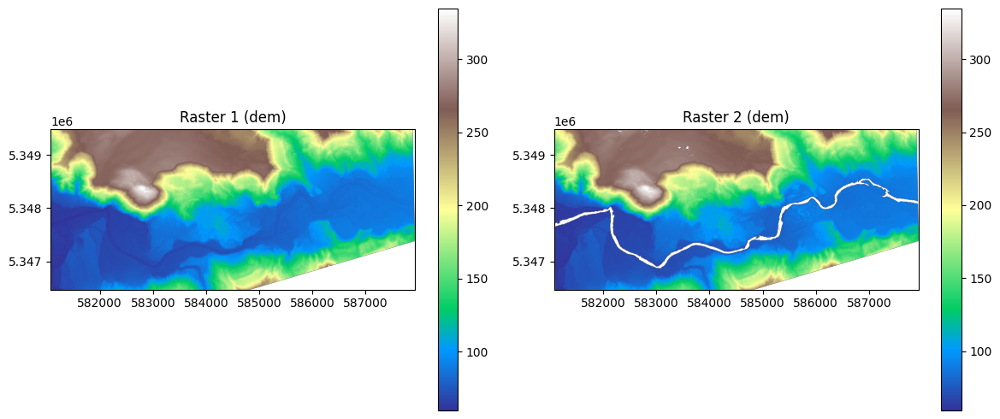

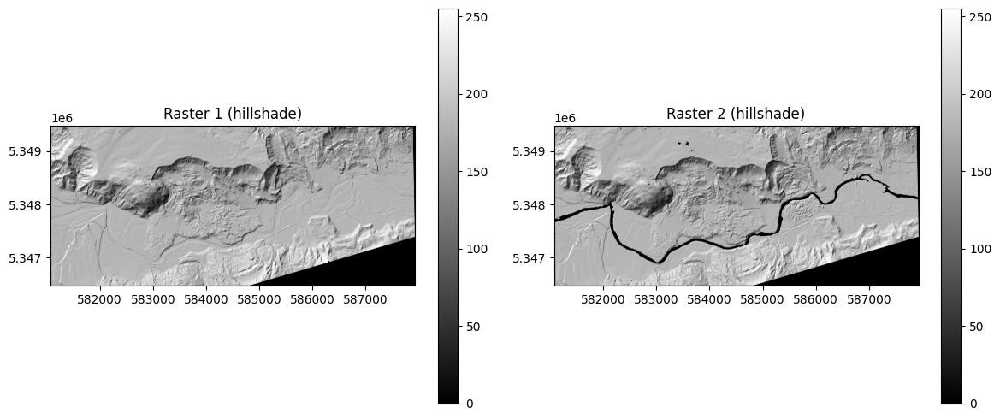

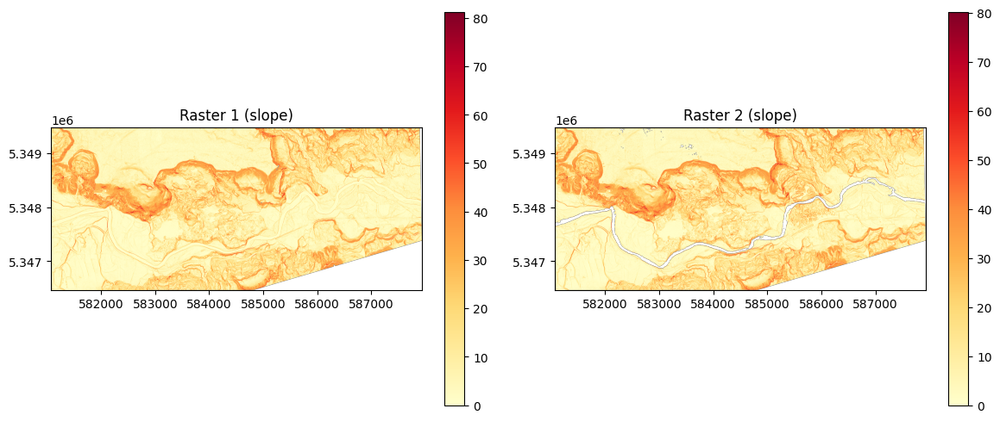

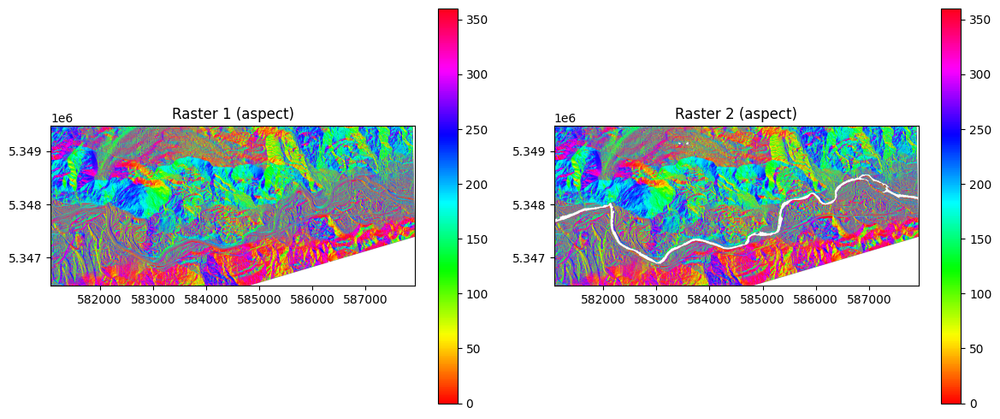

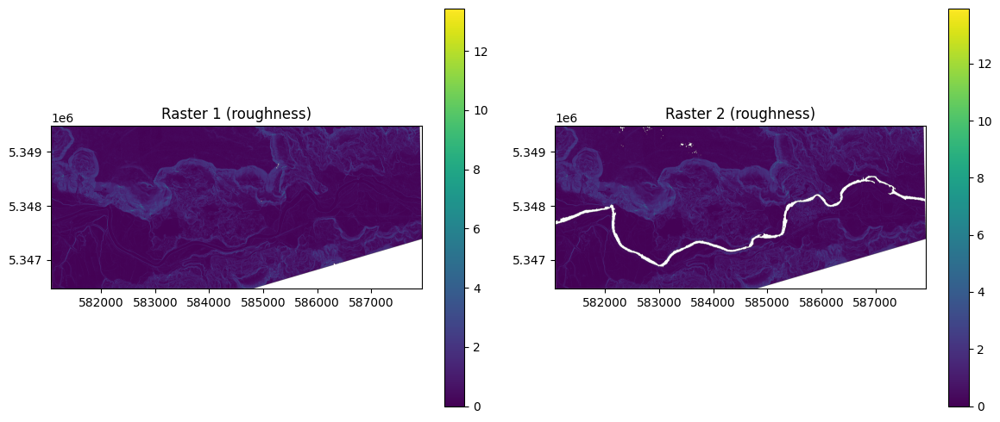

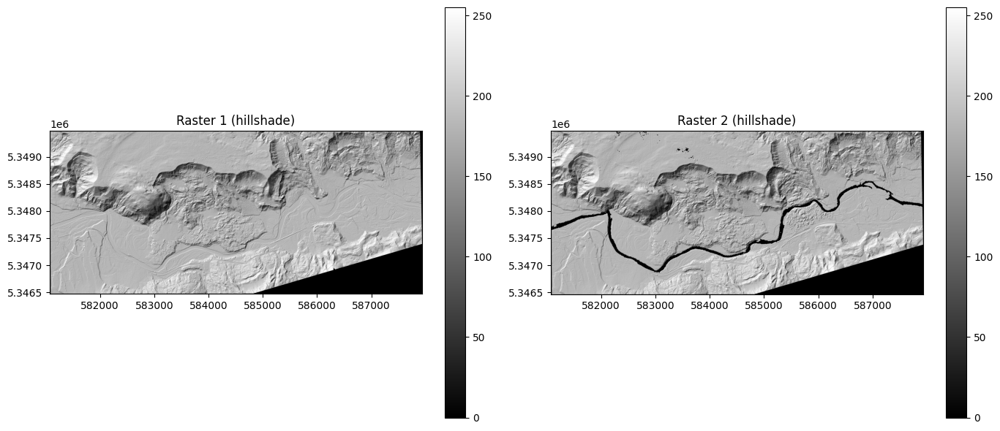

In [ ]:
# Generate derivatives for both rasters
hillshade1, hillshade2 = pair.generate_derivative("hillshade")
slope1, slope2 = pair.generate_derivative("slope")
aspect1, aspect2 = pair.generate_derivative("aspect")
roughness1, roughness2 = pair.generate_derivative("roughness")

# Plot side-by-side with automatic derivative generation
fig, axes = pair.plot_pair(derivative='dem')        # Original DEMs
fig, axes = pair.plot_pair(derivative='hillshade')  # Hillshades
fig, axes = pair.plot_pair(derivative='slope')      # Slopes
fig, axes = pair.plot_pair(derivative='aspect')     # Aspects
fig, axes = pair.plot_pair(derivative='roughness')  # Roughness

# Customize hillshade parameters
fig, axes = pair.plot_pair(
    derivative='hillshade',
    azimuth=270,    # West-facing light
    altitude=30,    # Low sun angle
    figsize=(14, 6)
)

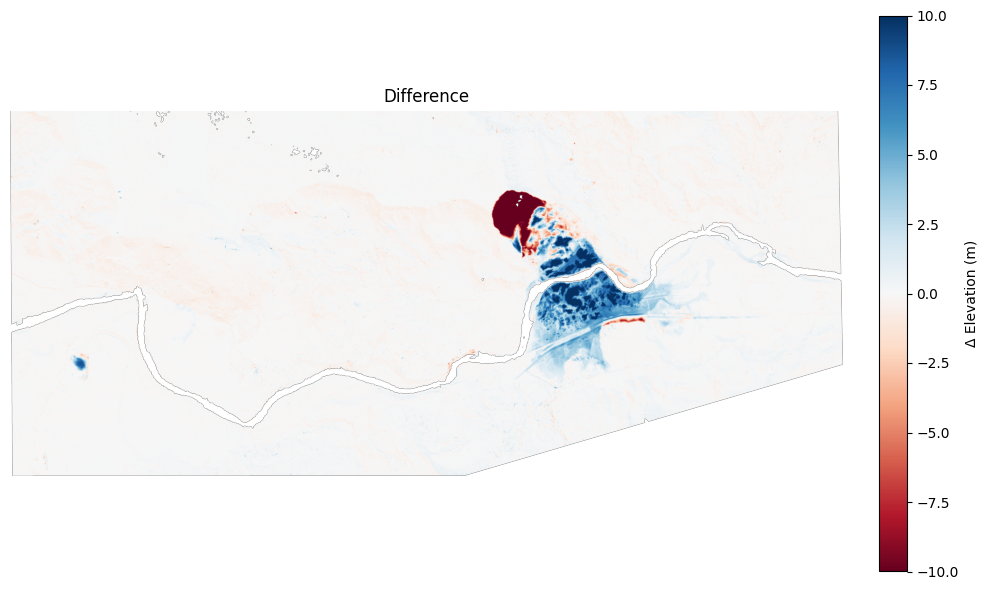

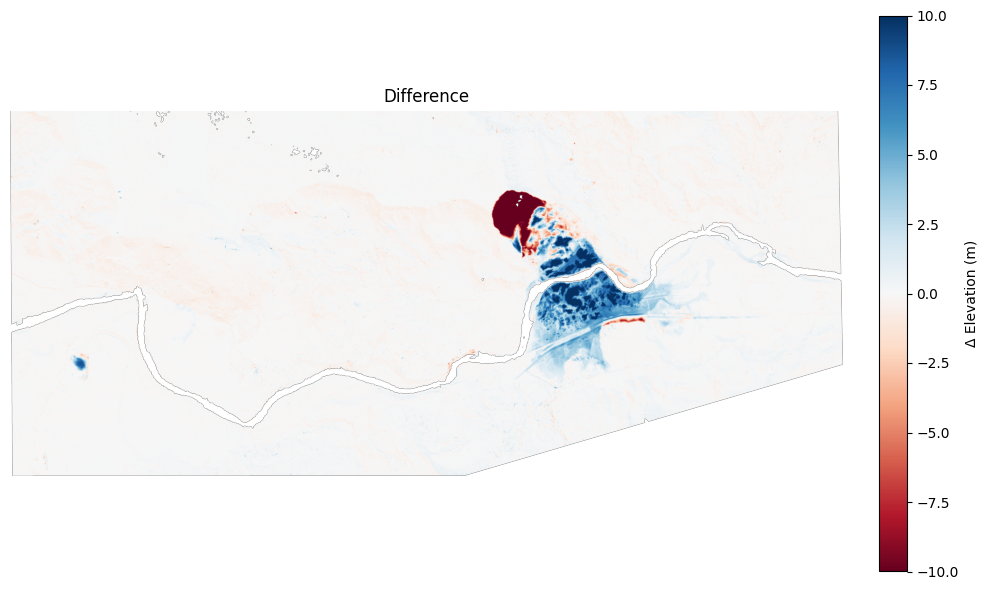

In [ ]:
pair.plot_difference(
    diff_path = DIFF_PATH,
    vmax = 10,
    vmin = -10,
    cmap = "RdBu"
)

## Question 2:

When looking at this difference image, what do positive and negative elevation change values indicate? The difference image is the compare image minus the reference image.

**Answer**:

<h2><a id="error_analysis"></a>5. Error analysis</h2>

Topographic differencing errors can be decomposed into three components:

1. **Systematic vertical bias** (μ): A constant offset between datasets, typically estimated as the median of stable-area differences to reduce outlier influence

2. **Spatially correlated random error**: Errors that exhibit spatial structure due to:
   - Point misclassification (meter to decameter scale)
   - Geometric distortion on slopes (decameter scale)
   - Horizontal alignment errors (hundred-meter scale)
   - Flight line striping (hundred-meter to kilometer scale)
   - Vertical datum inconsistencies (kilometer scale)

3. **Uncorrelated random noise** (nugget): High-frequency noise from sensor sensitivity, environmental conditions, and surface reflectivity ([Glennie, 2007](https://doi.org/10.1515/jag.2007.017))


<h3><a id="define_stable_areas"></a>Define stable areas</h3>

To minimize errors due to the above sources, we must define stable areas are regions where **no topographic change is expected** between surveys. They serve as control zones for error calibration and the elevation differences within these areas represent pure error, allowing us to characterize the spatial structure of uncertainty.

<h4><a id="good_stable_area"></a>What makes a good stable area?</h4>

**Ideal choices**:
- Roads and parking lots (paved, unvegetated)
- Flat, undisturbed terrain
- Areas with similar terrain properties (slope, roughness) to your areas of interest

**Areas to avoid**:
- Vegetation change zones (leaf-on vs. leaf-off)
- Active construction or development areas
- Water bodies (variable water levels)
- DEM boundary edges (edge effects)
- Areas with real expected change

**Use the interactive map below to draw polygons over areas you consider stable.**

**Instructions:**
1. Use the polygon tool to draw areas of no expected change
2. Select "Stable" from the layer dropdown when drawing
3. Aim for areas totaling at least 1 km² if you expect long-range correlations
4. Run the cells below after drawing your polygons


Good candidates at this site include the Whitman bench north of the headscarp, the valley floor west of the slide, and upland surfaces several kilometres west. Spread your stable areas out, because the long-range correlation structure is what will dominate the uncertainty on your volumes.

In [ ]:
diff = results.get("difference_raster")
assert str(diff.filename) == str(DIFF_PATH)

## Define Stable Areas

In [ ]:
out_folder_poly = POLY_DIR


interactor = TopoMapInteractor(
    topo_diff_path=diff.filename,
    hillshade_path=hillshade1.filename,
    output_dir=out_folder_poly,
    overlay_dpi=600,
    overlay_vmin=-10,
    overlay_vmax=10,
)

interactor.map

Overlay: shape=(3012, 6853), nodata=nan
Valid pixels: 18,647,365 / 20,641,236 (90.3%)
Color range: [-10.000, 10.000]
Data range: [-85.459, 20.400]
Saved overlay: /content/oso_output/polygons/difference-bccfb213dbbd4ed1aa5494c1e3b061fe.png
Generated data URL: 16782290 chars (12586699 bytes)
Map bounds (lat/lon): ((48.266234654702494, -121.9075129451114), (48.29241276368941, -121.81456036346893))
Map center: (48.27932370919595, -121.86103665429016)
Using overlay: /content/oso_output/polygons/difference-bccfb213dbbd4ed1aa5494c1e3b061fe.png


Map(center=[48.27932370919595, -121.86103665429016], controls=(ZoomControl(options=['position', 'zoom_in_text'…

In [ ]:
interactor.stable_geoms

[<POLYGON ((584991.533 5348693.67, 585063.375 5348786.794, 585145.325 5348838...>,
 <POLYGON ((584934.528 5347600.65, 585215.579 5347763.605, 585250.129 5348008...>,
 <POLYGON ((585194.915 5349144.406, 585224.397 5348874.918, 585636.481 534878...>]

In [ ]:
interactor.unstable_geoms

[]

<h3><a id="descriptive_stats"></a>Descriptive statistics</h3>

Before fitting a variogram, it is essential to examine the statistical characteristics of the stable area(s). Descriptive statistics provide a first-order assessment of the differencing errors and help evaluate whether the data meet the assumptions required for geostatistical analysis.

**Key statistics to examine:**

- **Mean and Median**: The median of the elevation differences in stable areas estimates the systematic vertical bias between the two DEMs. A non-zero median indicates a consistent offset that should be removed before variogram analysis. The mean is more sensitive to outliers, so comparing mean and median helps identify skewness in the distribution.

- **Standard Deviation and Variance**: These quantify the overall spread of elevation differences. High variance may indicate significant error sources or residual real change in areas assumed to be stable.

- **Skewness and Kurtosis**: Departures from normality can signal issues. Positive skewness might indicate unremoved vegetation or construction, while heavy tails (high kurtosis) could reflect outliers from misclassification or edge effects.

- **Percentiles (0.5%, 99.5%)**: Examining extreme percentiles helps identify outliers that may need to be filtered before variogram estimation.

**Assessing stationarity across stable areas:**

A fundamental assumption in geostatistics is *stationarity*: that the mean and variance of the error field are constant across the study area, and that spatial covariance depends only on separation distance, not absolute location ([Webster & Oliver, 2007](https://doi.org/10.1002/9780470517277)). Examining the statistics of each stable area *separately* provides a practical check:

1. **Compare means/medians across areas**: Substantially different median values may indicate spatially varying bias (e.g., from flight line effects or tilted datums), violating the assumption that a single variogram model applies everywhere.

2. **Compare variances across areas**: If one stable area has much higher variance than another, the error characteristics may depend on location or terrain properties. This *heteroscedasticity* suggests that a single variogram may not adequately represent error structure across the entire scene ([Hugonnet et al., 2022](https://doi.org/10.1109/JSTARS.2022.3188922)).

3. **Look for systematic patterns**: If stable areas on one side of the scene consistently show positive differences while those on the other side show negative differences, a regional trend or tilt may be present that should be modeled separately.

The table and histogram below summarize the distribution of elevation differences in your stable area(s). If you have defined multiple stable polygons, compare their individual statistics to assess spatial consistency.

In [ ]:
stable_polys, _ = interactor.export_geodataframes()

# one combined mask
rasterizer_stable = StableAreaRasterizer(interactor.topo_diff.path, stable_polys, nodata=-9999)
analyzer_stable = StableAreaAnalyzer(rasterizer_stable)

# Combined-area stats
df_all_stable_polys = analyzer_stable.stats_all(POLY_DIR / "combined_stable.tif")

# Per-area stats
df_each_stable_poly = analyzer_stable.stats_each(POLY_DIR / "each_stable")


2026-11-09 18:42:27,303 - WARNING - CPLE_IllegalArg in combined_stable.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-09 18:42:31,836 - WARNING - CPLE_IllegalArg in stable_area_0.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-09 18:42:32,287 - WARNING - CPLE_IllegalArg in stable_area_1.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-09 18:42:32,558 - WARNING - CPLE_IllegalArg in stable_area_2.tif: BLOCKXSIZE can only be used with TILED=YES


In [ ]:
df_all_stable_polys

,mean,median,mode,std,variance,min,max,skewness,kurtosis,0.5_percentile,99.5_percentile
all_areas,-0.07074,-0.050514,-0.021729,0.253057,0.064038,-12.059769,7.612991,-0.464509,27.982697,-0.901217,0.765469


In [ ]:
df_each_stable_poly

,mean,median,mode,std,variance,min,max,skewness,kurtosis,0.5_percentile,99.5_percentile
area_id,,,,,,,,,,,
0,-0.001165,0.001160,-0.007812,0.148316,0.021998,-2.008636,1.843384,-0.246719,5.737368,-0.478790,0.451051
1,-0.095040,-0.068443,-0.044312,0.266720,0.071140,-12.059769,7.612991,-0.166269,30.601953,-0.928982,0.830670
2,-0.062896,-0.049713,-0.049316,0.289624,0.083882,-5.218536,2.374054,-0.943740,12.668149,-1.038649,0.823683


## Question 3:

Are your stable polygons similar? What does similarity mean for this dataset?
If your stable polygons are not similar, what are some reasons that could be contributing to this?

**Answer**:

In [ ]:
# Checks on the difference raster and the stable areas before they are used.
stable_mask_path = POLY_DIR / "combined_stable.tif"

def _vals(path):
    with rasterio.open(path) as src:
        a = src.read(1).astype(float)
        nd = src.nodata
    a = a[np.isfinite(a)]
    if nd is not None and np.isfinite(nd):
        a = a[a != nd]
    return a

d = _vals(diff.filename)
s = _vals(stable_mask_path)

def _row(name, a):
    med = np.median(a)
    print(f"  {name:12s} {a.size:>12,} {med:+9.4f} "
          f"{1.4826*np.median(np.abs(a-med)):8.4f} {a.std():8.4f} "
          f"{a.min():10.4f} {a.max():9.4f}")

print(f"  {'':12s} {'n':>12s} {'median':>9s} {'NMAD':>8s} {'std':>8s} {'min':>10s} {'max':>9s}")
_row("difference", d)
_row("stable", s)

# compute_difference reports stats on its in-memory array; compare with the file
st = results.get("stats") or {k: results[k] for k in
     ("count_valid","min","max","median","nmad") if k in results}
if st:
    print(f"\n  compute_difference() reported vs difference raster on disk:")
    for k, v in (("count_valid", d.size), ("min", d.min()), ("max", d.max()),
                 ("median", np.median(d)), ("nmad", 1.4826*np.median(np.abs(d-np.median(d))))):
        r = st.get(k)
        if r is not None:
            print(f"    {k:12s} reported {r:>14,.4f}   on disk {v:>14,.4f}")

print(f"\n  stable mask covers {s.size/d.size:.1%} of the valid difference raster")

flags = []
if s.size / d.size > 0.5:
    flags.append("stable mask covers >50% of the scene")
lim = max(abs(s.min()), abs(s.max()))
if lim > 5:
    flags.append(f"stable mask contains |dz| up to {lim:.1f} m")
if s.std() > 2 * (1.4826*np.median(np.abs(s-np.median(s)))):
    flags.append("std >> NMAD: heavy tails from real change inside the stable mask")
med_all = float(df_all_stable_polys["median"].iloc[0])
off = df_each_stable_poly[(df_each_stable_poly["median"] - med_all).abs() > 0.25]
if len(off):
    flags.append(f"stable areas {list(off.index)} differ from the combined median by >0.25 m")
tiny = df_each_stable_poly[df_each_stable_poly["std"] == 0]
if len(tiny):
    flags.append(f"stable areas {list(tiny.index)} have zero variance (too few pixels)")

print()
for f in flags:
    print(f"  CHECK: {f}")
if not flags:
    print("  no issues flagged")

                          n    median     NMAD      std        min       max
  difference     18,647,365   -0.0245   0.1682   3.5772   -85.4587   20.4002
  stable          4,686,349   -0.0505   0.1613   0.2531   -12.0598    7.6130

  compute_difference() reported vs difference raster on disk:
    count_valid  reported 18,647,365.0000   on disk 18,647,365.0000
    min          reported       -85.4587   on disk       -85.4587
    max          reported        20.4002   on disk        20.4002
    median       reported        -0.0245   on disk        -0.0245
    nmad         reported         0.1682   on disk         0.1682

  stable mask covers 25.1% of the valid difference raster

  CHECK: stable mask contains |dz| up to 12.1 m


<h3><a id="estimate-error"></a>Estimate systematic error</h3>


Systematic error (vertical bias) represents a constant offset between the two DEMs that affects all elevation differences uniformly. This bias can arise from instrument calibration errors, incorrect atmospheric corrections, GNSS/IMU misalignments, or inconsistencies in vertical coordinate reference systems such as mismatched geoid models ([Glennie, 2007](https://doi.org/10.1515/jag.2007.017); [Habib et al., 2009](https://doi.org/10.14358/PERS.75.9.1093)). Geoid errors typically produce shifts of 10–20 cm, while confusion between ellipsoidal and orthometric heights can cause offsets of tens of meters.

**Why use the median?**

We estimate vertical bias as the **median** of elevation differences in stable areas rather than the mean. The median is more robust to outliers (isolated large values from real change, misclassification, or edge effects), so the bias estimate reflects the typical offset rather than being skewed by anomalous values (Brigham et al., 2026).

**Interpreting the bias:**

- A non-zero median indicates systematic offset that should be removed before variogram analysis
- The bootstrap uncertainty quantifies confidence in the bias estimate
- After bias removal, the distribution should be approximately centered on zero

**Important considerations:**

- If you observe widespread real change (e.g., regional uplift from an earthquake or isostatic rebound), this signal will be absorbed into the bias estimate and must be accounted for separately
- For DSM differencing, vegetation changes (leaf-on vs. leaf-off) can bias the median; consider estimating bias from DTM results instead
- Very large biases (>1 m) may indicate datum errors that should be investigated before proceeding

In [ ]:
# Load the stable area raster (this is the masked difference raster)
stable_area_path = POLY_DIR / "combined_stable.tif"
stable_area = Raster.from_file(stable_area_path)

# Get the median from the stable area
# Read the data directly with rasterio to get valid values

with rasterio.open(stable_area_path) as src:
    data = src.read(1)
    nodata = src.nodata
    # Mask nodata values
    if nodata is not None:
        valid_data = data[data != nodata]
    else:
        valid_data = data[np.isfinite(data)]

    diff_stable_median = np.median(valid_data)
    print(f"Median of stable area differences: {diff_stable_median:.4f} m")

# Set up paths and parameters
output_path = POLY_DIR / "combined_stable_bias_removed.tif"
unit = "m"
dem_resolution = 1.0

# Load raster data using RasterDataHandler
raster_data_handler = RasterDataHandler(stable_area_path, unit, dem_resolution)
raster_data_handler.load_raster()

# Get the data array
vert_diff_array = raster_data_handler.data_array

# Measure of vertical bias (median)
vertical_bias = np.median(vert_diff_array)
print(f"Vertical bias: {vertical_bias:.4f} m")

# Get uncertainty in the median value by bootstrap resampling
stats = StatisticalAnalysis(raster_data_handler)
median_uncertainty = stats.bootstrap_uncertainty_subsample(n_bootstrap=1000, subsample_proportion=0.1)
print(f"Median uncertainty (bootstrap): {median_uncertainty:.4f} m")

# Subtract the vertical bias from the stable area raster and save
raster_data_handler.subtract_value_from_raster(output_path, vertical_bias)
print(f"Saved bias-removed raster to: {output_path}")

# Create new RasterDataHandler for the modified raster
raster_bias_removed = RasterDataHandler(output_path, unit, dem_resolution)
raster_bias_removed.load_raster()

print(f"\nBias-removed stats:")
print(f"  Mean: {np.mean(raster_bias_removed.data_array):.4f} m")
print(f"  Median: {np.median(raster_bias_removed.data_array):.4f} m")
print(f"  Std: {np.std(raster_bias_removed.data_array):.4f} m")

Median of stable area differences: -0.0505 m
Vertical bias: -0.0505 m
Median uncertainty (bootstrap): 0.0001 m
Saved bias-removed raster to: /content/oso_output/polygons/combined_stable_bias_removed.tif

Bias-removed stats:
  Mean: -0.0202 m
  Median: 0.0000 m
  Std: 0.2531 m


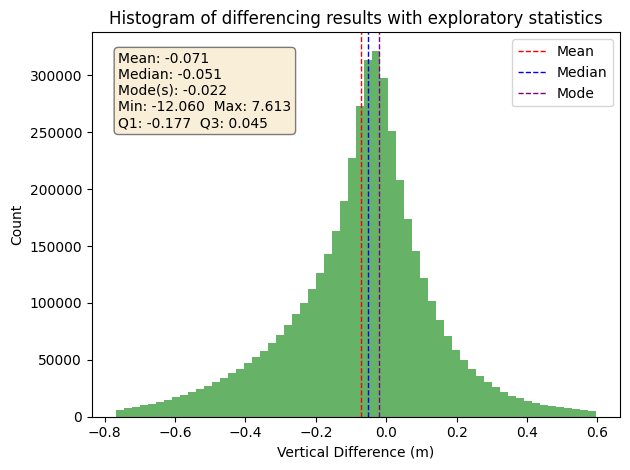

In [ ]:
fig = stats.plot_data_stats()

## Question 4:

Do your stable polygons have a systemic bias?  What could a negative bias indicate?  How about a positive bias? Is your bias a reasonable estimate for this dataset? Why or why not?

**Answer**:

<h3><a id="Variography"></a>Variography</h3>


Variography is the process of estimating and modeling the spatial covariance structure of your data. For topographic differencing, we analyze how elevation errors are correlated across space ([Webster & Oliver, 2007](https://doi.org/10.1002/9780470517277); [Oliver & Webster, 2014](https://doi.org/10.1016/j.catena.2013.09.006)).

<h4><a id="semivariogram"></a>The semivariogram</h4>

The **semivariogram** γ(h) measures the average squared difference between values separated by distance h (Matheron, 1965):

$$\gamma(h) = \frac{1}{2N(h)} \sum_{i=1}^{N(h)} [z(x_i) - z(x_i + h)]^2$$

At small distances, nearby points tend to have similar errors (low semivariance). As distance increases, the correlation breaks down and semivariance increases until it reaches a plateau (the sill).

The variogram has several key features:

1. **Nugget (c₀)**: The y-intercept, representing measurement noise and microscale variability below the sampling resolution

2. **Sill (c)**: The plateau value representing total variance. When the variogram reaches the sill, points are no longer spatially correlated.

3. **Range (a)**: The distance at which the sill is reached. Beyond this distance, errors are independent.

<h4><a id="nested_variogram"></a>Nested variograms for multi-scale error</h4>

Lidar differencing errors operate at multiple scales simultaneously. A **nested variogram** captures this:

$$\gamma(h) = c_0 + \sum_{i=1}^{n} c_i \cdot \text{model}_i(h, a_i)$$

where each component (i) has its own partial sill (cᵢ) and range (aᵢ). For example:
- Component 1 (range approx 30 m): Point classification errors
- Component 2 (range approx 500 m): Flight line alignment errors
- Component 3 (range approx 2 km): Geoid/datum inconsistencies

<h4><a id="model_selection"></a>Model Selection</h4>

We fit nested spherical models and select the best using:
- **AIC (Akaike Information Criterion)**: Balances fit quality vs. model complexity
- **Cross-validation**: Tests predictive performance on held-out data

The spherical model is commonly used because it has a finite range, provides smooth transitions, and handles nesting well ([Webster & Oliver, 2007](https://doi.org/10.1002/9780470517277)).

In [ ]:
gv = GridVariogram(raster_bias_removed, n_realizations=3)
gv.run(
    area_side=250, samples_per_area=400, max_samples=10_000_000,
    bin_width=10, max_lag_multiplier=1/3,
    estimator="matheron", n_samples=10, model_types = ["spherical", "exponential", "gaussian"],
    criterion="aicc", seed=42, verbose=True,
)

  [1/3] spherical + spherical  AICc=2209.1
  [2/3] spherical + spherical  AICc=2232.7
  [3/3] spherical + exponential  AICc=2219.1


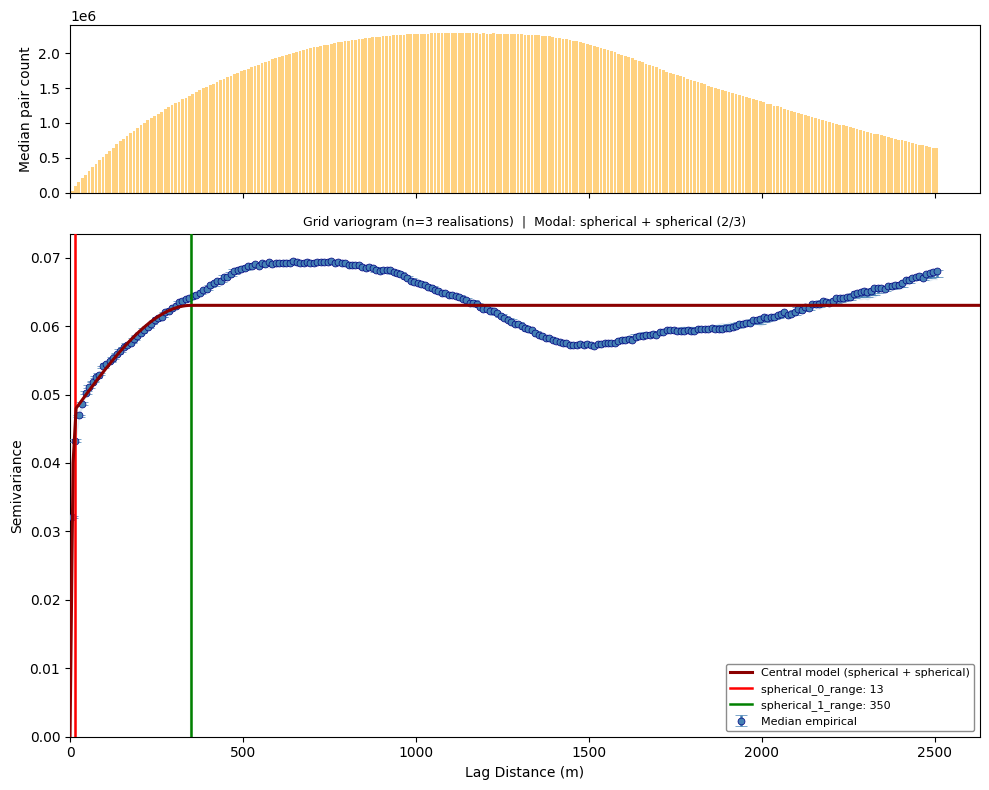

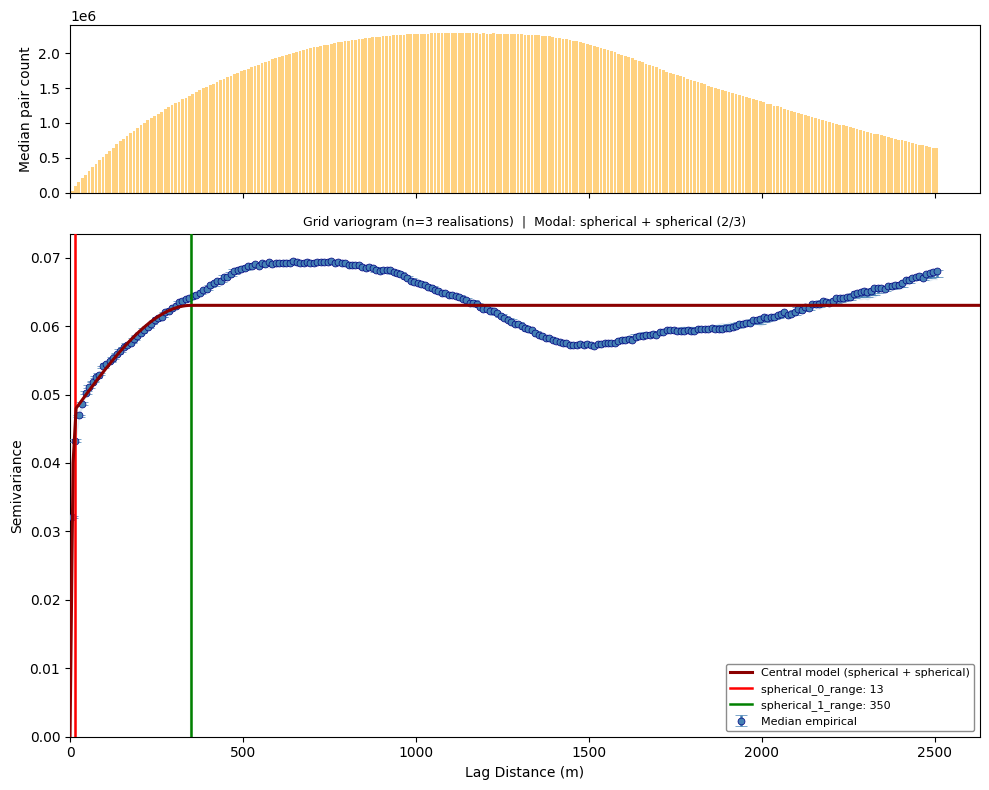

In [ ]:
gv.plot_variogram(include_central_model=True,include_bootstrap=True)

<h3><a id="uncertainty_propagation"></a>Uncertainty propagation</h3>

Once we have a fitted variogram model, we can propagate uncertainty to any area of interest ([Rolstad et al., 2009](https://doi.org/10.3189/002214309789470950)). This is the key step that transforms error characterization into actionable uncertainty bounds.

For a spatially averaged elevation change over an area A, the regional variance σ²_A depends on the spatial covariance structure:

$$\sigma_A^2 = \frac{1}{A^2} \int_A \int_A [\sigma_{\Delta_z}^2 - \gamma(h)] \, dx \, dy$$

**Intuition**: If all points in your area are highly correlated (small area relative to the range), errors move together and uncertainty is high. If points are spread over a large area with mixed positive and negative errors that partially cancel, uncertainty decreases.

A crucial insight: **uncertainty decreases as the area of aggregation increases**, but at different rates depending on the variogram parameters:
- Features smaller than the correlation range: errors are correlated and don't cancel out (uncertainty ≈ √sill)
- Features much larger than the correlation range: errors average toward zero (uncertainty ≈ √(sill / n_effective))

With a nested variogram, each component contributes independently:

$$\sigma_{total}^2 = \sigma_{nugget}^2 + \sigma_{short}^2 + \sigma_{mid}^2 + \sigma_{long}^2$$

For irregularly shaped polygons, we use **Monte Carlo integration**: randomly sample N pairs of points within the polygon, compute covariances using the fitted variogram, and average to approximate the double integral (approx 10,000–25,000 pairs).

<h4><a id="features_of_interest"></a>Draw features of interest (unstable areas)</h4>

Use the interactive map below to draw polygons around areas where you expect topographic change (e.g., landslides, construction sites, eroded channels, deposited sediment bars). The uncertainty will be calculated for each polygon.

## Define Unstable Areas on the Map Below

## Question 5:

Should you define one unstable polygon or several? Should source and deposit regions be separated? Is it possible to fully separate these regions from a difference DEM? Why or why not?

**Answer**:

In [ ]:
interactor.map

Map(bottom=5812756.0, center=[48.28130803352071, -121.85369968414308], controls=(ZoomControl(options=['positio…

In [ ]:
interactor.unstable_geoms

[<POLYGON ((585228.595 5348807.609, 585142.716 5348799.987, 585080.018 534873...>]

In [ ]:
_, unstable_polys = interactor.export_geodataframes()

In [ ]:
from shapely.ops import unary_union
_all_features = unary_union(list(unstable_polys['geometry']))

# Calculate uncertainty for each feature of interest
uncertainties_per_feature = []

for i, poly in enumerate(unstable_polys['geometry']):
    print(f"\nProcessing polygon {i+1}/{len(unstable_polys)}...")

    estimator = RegionalUncertaintyEstimator(
        raster_data_handler=raster_bias_removed,
        variogram_analysis=gv,
        area_of_interest=poly,
        unstable_geoms=_all_features,
        fitted_model=gv.fitted_model,
    )

    estimator.calc_total_uncertainty(n_pairs=25_000, seed=SEED, include_bias_se=True)
    print(f"  median (bias) SE: {estimator.sigma_a_stable:.4f} m"
          f"  [{estimator.stable_geom_source}]")
    uncertainties_per_feature.append(estimator)

# Print detailed summary for first polygon
print("\n")
print(uncertainties_per_feature[0].summary())


Processing polygon 1/1...
  median (bias) SE: 0.0148 m  [footprint_minus_unstable]


REGIONAL UNCERTAINTY SUMMARY
Polygon area: 1211462.33 m²
Total variance (σ²): 0.063038; min: 0.062938; max: 0.063050
σ_A interval method: realization_bands — realization-ensemble envelope — p16/p84 sensitivity spread, NOT a calibrated CI

Uncorrelated σ₀: 0.253864
Uncorrelated (polygon mean): 0.000231
Median (bias) SE, correlation-aware: ± 0.014823  [footprint minus unstable areas]
  (reported alongside the totals; calc_total_uncertainty(include_bias_se=True) folds it in)

POLYGON CORRELATED UNCERTAINTY:
  Total: 0.028990; min: 0.028399; max: 0.028639

POLYGON TOTAL UNCERTAINTY:
  Total: 0.032561; min: 0.032036; max: 0.032248

----------------------------------------------------------------------
RASTER CORRELATED UNCERTAINTY:
  Uncorrelated (raster mean): 0.000117
  Total: 0.014823; min: 0.014626; max: 0.014759

RASTER TOTAL UNCERTAINTY:
  Total: 0.020963; min: 0.020824; max: 0.020918


---

<h2><a id="volume"></a>8. Volume change and its uncertainty</h2>

Volume over a polygon is the sum of the differences:

$$V = \sum_i \Delta z_i \cdot a \qquad (a = \text{cell area})$$

Since $V = A \cdot \langle \Delta z \rangle$, the standard error scales **linearly** with area:

$$\sigma_V = A \cdot \sigma_{\Delta H}$$

Three volumes are reported for each polygon:

- **net**: signed; erosion and deposition cancel.
- **gross cut**: total lowering, positive magnitude.
- **gross fill**: total raising.

A polygon drawn around a whole landslide contains both source and deposit, so its **net** volume is small (the cut and fill nearly cancel). Report cut and fill separately if you want the volume of material removed or emplaced.

Uncertainty is propagated over the polygon as three independent terms combined in quadrature, then scaled to volume by the area ([Anderson, 2019](https://doi.org/10.1002/esp.4551), Eq. 21–22):

$$\sigma_V = A\sqrt{\;\underbrace{\sigma_{rms}^2/n}_{\text{uncorrelated}} \;+\; \underbrace{\sigma_{sc}^2 \,\tfrac{\pi a^2}{5nL^2}}_{\text{spatially correlated}} \;+\; \underbrace{\sigma_{sys}^2}_{\text{systematic}}}$$


In [ ]:
from topochange import VolumeEstimator

full_bias_removed_path = OUT_DIR / "difference_bias_removed.tif"

raster_diff_full = RasterDataHandler(diff.filename, unit, dem_resolution)
raster_diff_full.load_raster()
raster_diff_full.subtract_value_from_raster(full_bias_removed_path, vertical_bias)

raster_full_bias_removed = RasterDataHandler(full_bias_removed_path, unit, dem_resolution)
raster_full_bias_removed.load_raster()

a = raster_full_bias_removed.data_array
print(f"n      {a.size:,}")
print(f"median {np.median(a):+.4f} m")
print(f"min    {a.min():+.4f} m")
print(f"max    {a.max():+.4f} m")

n      18,647,365
median +0.0260 m
min    -85.4082 m
max    +20.4507 m


In [ ]:
# Stable geometry is passed explicitly so sigma_0 comes from the same terrain
# the variogram was fitted on.
stable_union = unary_union(list(stable_polys['geometry']))

volume_results = []

for i, poly in enumerate(unstable_polys['geometry']):
    label = unstable_polys.iloc[i].get('name', f'feature {i+1}')

    est_vol = RegionalUncertaintyEstimator(
        raster_data_handler=raster_full_bias_removed,
        variogram_analysis=gv,
        area_of_interest=poly,
        stable_geoms=stable_union,
        fitted_model=gv.fitted_model,
    )
    est_vol.calc_total_uncertainty(n_pairs=25_000, seed=SEED, include_bias_se=True)

    vol = VolumeEstimator(est_vol, area_basis="valid").compute(
        lod=None,
        include_bias_se=True,     # Anderson (2019) Eq. 21
    )
    volume_results.append((label, est_vol, vol))

    print(f"{label}")
    print(f"  polygon area   {vol.area_polygon:>14,.0f} m2")
    print(f"  valid area     {vol.area_valid:>14,.0f} m2   ({vol.frac_valid:.1%})")
    print(f"  mean dz        {vol.mean_dh:>14.3f} m")
    print(f"  sigma_dH       {est_vol.total_uncertainty_polygon:>14.4f} m")
    print(f"  net volume     {vol.v_net:>14,.0f} m3   +/- {vol.sigma_v:,.0f}")
    print(f"  gross cut      {vol.v_cut:>14,.0f} m3")
    print(f"  gross fill     {vol.v_fill:>14,.0f} m3")
    print(f"  sigma_0        {est_vol.sigma0_uncorrelated:>14.4f} m")
    print(f"  sigma_V terms  uncorrelated {vol.sigma_v_uncorr:>12,.0f}")
    print(f"                 correlated   {vol.sigma_v_corr:>12,.0f}")
    print(f"                 systematic   {vol.sigma_v_bias:>12,.0f}")
    print()

FOI_1
  polygon area        1,211,462 m2
  valid area          1,143,502 m2   (94.4%)
  mean dz                -0.491 m
  sigma_dH               0.0328 m
  net volume           -561,072 m3   +/- 37,478
  gross cut           4,366,355 m3
  gross fill          3,805,283 m3
  sigma_0                0.2539 m
  sigma_V terms  uncorrelated          264
                 correlated         33,151
                 systematic         17,480



In [ ]:
import pandas as pd

vol_df = pd.DataFrame([{
    "feature":       label,
    "area_ha":       vol.area_used / 1e4,
    "mean_dz_m":     vol.mean_dh,
    "sigma_dH_m":    est_vol.total_uncertainty_polygon,
    "net_m3":        vol.v_net,
    "sigma_V_m3":    vol.sigma_v,
    "cut_m3":        vol.v_cut,
    "fill_m3":       vol.v_fill,
    "sigma_V_naive": vol.sigma_v_naive,
    "sigma_V_full":  vol.sigma_v_fullcorr,
} for label, est_vol, vol in volume_results]).set_index("feature")

display(vol_df.round(3))

n_real = getattr(gv, "n_realizations", 1)
if n_real < 2:
    print(f"n_realizations = {n_real}: sigma_V interval bounds are not resolved "
          f"(min = max = central). Set n_realizations >= 2 in GridVariogram for an envelope.")

,area_ha,mean_dz_m,sigma_dH_m,net_m3,sigma_V_m3,cut_m3,fill_m3,sigma_V_naive,sigma_V_full
feature,,,,,,,,,
FOI_1,114.35,-0.491,0.033,-561071.596,37478.005,4366354.963,3805283.367,271.468,290293.425


---

<h2><a id="interpretation"></a>9. Interpreting the volume</h2>

The published volume of the 2014 landslide is approx 8 × 10⁶ m³ (Iverson et al., 2015, as cited in Wartman et al., 2016).

In [ ]:
published_volume = 8.0e6   # m3, Iverson et al. (2015), as cited in Wartman et al. (2016)

total_cut  = sum(v.v_cut for _, _, v in volume_results)
total_fill = sum(v.v_fill for _, _, v in volume_results)
total_net  = sum(v.v_net for _, _, v in volume_results)

print(f"{'':22s} {'m3':>14s}")
for label, est_vol, vol in volume_results:
    print(f"{label:22s} {vol.v_net:>14,.0f}  +/- {vol.sigma_v:,.0f}")
print(f"{'-'*52}")
print(f"{'gross cut':22s} {total_cut:>14,.0f}")
print(f"{'gross fill':22s} {total_fill:>14,.0f}")
print(f"{'net':22s} {total_net:>14,.0f}")
print()
print(f"{'published (mobilized)':22s} {published_volume:>14,.0f}")

                                   m3
FOI_1                        -561,072  +/- 37,478
----------------------------------------------------
gross cut                   4,366,355
gross fill                  3,805,283
net                          -561,072

published (mobilized)       8,000,000


## Question 6:

In this scenario what does gross cut and gross fill represent?  What are some reasons it may be impossible to separate cut and fill areas completely?


## Question 7:

The net volume change should be negative. Why?


## Question 8:

What are some reasons that net vertical change (what we've calculated) is different from the published volume found in the literature?

**Answers**:

---

<h2><a id="references"></a>References</h2>

<h3>The Oso / SR 530 landslide and the North Fork Stillaguamish valley</h3>

- LaHusen, S.R., Duvall, A.R., Booth, A.M. & Montgomery, D.R. (2016). Surface roughness dating of long-runout landslides near Oso, Washington (USA), reveals persistent postglacial hillslope instability. *Geology*, 44(2), 111–114. [https://doi.org/10.1130/G37267.1](https://doi.org/10.1130/G37267.1)

- Wartman, J., Montgomery, D.R., Anderson, S.A., Keaton, J.R., Benoît, J., dela Chapelle, J. & Gilbert, R. (2016). The 22 March 2014 Oso landslide, Washington, USA. *Geomorphology*, 253, 275–288. [https://doi.org/10.1016/j.geomorph.2015.10.022](https://doi.org/10.1016/j.geomorph.2015.10.022)

<h3>Differencing, uncertainty and volumes</h3>

- Albino, F., Smets, B., d'Oreye, N. & Kervyn, F. (2015). High‐resolution TanDEM‐X DEM: An accurate method to estimate lava flow volumes at Nyamulagira Volcano (D.R. Congo). *Journal of Geophysical Research: Solid Earth*, 120, 4189–4207. [https://doi.org/10.1002/2015JB011988](https://doi.org/10.1002/2015JB011988)

- Anderson, S.W. (2019). Uncertainty in quantitative analyses of topographic change: error propagation and the role of thresholding. *Earth Surface Processes and Landforms*, 44, 1015–1033. [https://doi.org/10.1002/esp.4551](https://doi.org/10.1002/esp.4551)

- Besl, P.J. & McKay, N.D. (1992). Method for registration of 3-D shapes. *Sensor Fusion IV: Control Paradigms and Data Structures*, SPIE, 586–606. [https://doi.org/10.1117/12.57955](https://doi.org/10.1117/12.57955)

- Brasington, J. & Smart, R.M.A. (2003). Close range digital photogrammetric analysis of experimental drainage basin evolution. *Earth Surface Processes and Landforms*, 28, 231–247. [https://doi.org/10.1002/esp.480](https://doi.org/10.1002/esp.480)

- Brasington, J., Langham, J. & Rumsby, B. (2003). Methodological sensitivity of morphometric estimates of coarse fluvial sediment transport. *Geomorphology*, 53, 299–316. [https://doi.org/10.1016/S0169-555X(02)00320-3](https://doi.org/10.1016/S0169-555X(02)00320-3)

- Dehecq, A., Gardner, A.S., Alexandrov, O., McMichael, S., Hugonnet, R., Shean, D. & Marty, M. (2020). Automated Processing of Declassified KH-9 Hexagon Satellite Images for Global Elevation Change Analysis Since the 1970s. *Frontiers in Earth Science*, 8, 566802. [https://doi.org/10.3389/feart.2020.566802](https://doi.org/10.3389/feart.2020.566802)

- DeLong, S.B., Hammer, M.N., Engle, Z.T., Richard, E.M., Breckenridge, A.J., Gran, K.B., Jennings, C.E. & Jalobeanu, A. (2022). Regional-Scale Landscape Response to an Extreme Precipitation Event From Repeat Lidar and Object-Based Image Analysis. *Earth and Space Science*, 9(12), e2022EA002420. [https://doi.org/10.1029/2022EA002420](https://doi.org/10.1029/2022EA002420)

- Glennie, C.L., Hinojosa‐Corona, A., Nissen, E., Kusari, A., Oskin, M.E., Arrowsmith, J.R. & Borsa, A. (2014). Optimization of legacy lidar data sets for measuring near‐field earthquake displacements. *Geophysical Research Letters*, 41, 3494–3501. [https://doi.org/10.1002/2014GL059919](https://doi.org/10.1002/2014GL059919)

- Glennie, C. (2007). Rigorous 3D error analysis of kinematic scanning LIDAR systems. *Journal of Applied Geodesy*, 1, 147–157. [https://doi.org/10.1515/jag.2007.017](https://doi.org/10.1515/jag.2007.017)

- Habib, A., Bang, K.I., Kersting, A.P. & Lee, D.-C. (2009). Error budget of lidar systems and quality control of the derived data. *Photogrammetric Engineering & Remote Sensing*, 75(9), 1093–1108. [https://doi.org/10.14358/PERS.75.9.1093](https://doi.org/10.14358/PERS.75.9.1093)

- Heritage, G.L., Milan, D.J., Large, A.R.G. & Fuller, I.C. (2009). Influence of survey strategy and interpolation model on DEM quality. *Geomorphology*, 112, 334–344. [https://doi.org/10.1016/j.geomorph.2009.06.024](https://doi.org/10.1016/j.geomorph.2009.06.024)

- Hugonnet, R., Brun, F., Berthier, E., Dehecq, A., Mannerfelt, E.S., Eckert, N. & Farinotti, D. (2022). Uncertainty analysis of digital elevation models by spatial inference from stable terrain. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 15, 6456–6472. [https://doi.org/10.1109/JSTARS.2022.3188922](https://doi.org/10.1109/JSTARS.2022.3188922)

- Izumida, A., Uchiyama, S. & Sugai, T. (2017). Application of UAV-SfM photogrammetry and aerial lidar to a disastrous flood: repeated topographic measurement of a newly formed crevasse splay of the Kinu River, central Japan. *Natural Hazards and Earth System Sciences*, 17, 1505–1519. [https://doi.org/10.5194/nhess-17-1505-2017](https://doi.org/10.5194/nhess-17-1505-2017)

- Journel, A.G. & Huijbregts, C.J. (1978). *Mining Geostatistics*. Academic Press.

- Lane, S.N., Westaway, R.M. & Hicks, D.M. (2003). Estimation of erosion and deposition volumes in a large, gravel‐bed, braided river using synoptic remote sensing. *Earth Surface Processes and Landforms*, 28, 249–271. [https://doi.org/10.1002/esp.483](https://doi.org/10.1002/esp.483)

- Langridge, R.M., Ries, W.F., Farrier, T., Barth, N.C., Khajavi, N. & De Pascale, G.P. (2014). Developing sub 5-m LiDAR DEMs for forested sections of the Alpine and Hope faults, South Island, New Zealand: Implications for structural interpretations. *Journal of Structural Geology*, 64, 53–66. [https://doi.org/10.1016/j.jsg.2013.11.007](https://doi.org/10.1016/j.jsg.2013.11.007)

- Lucieer, A., de Jong, S.M. & Turner, D. (2014). Mapping landslide displacements using Structure from Motion (SfM) and image correlation of multi-temporal UAV photography. *Progress in Physical Geography*, 38, 97–116. [https://doi.org/10.1177/0309133313515293](https://doi.org/10.1177/0309133313515293)

- Matheron, G. (1965). *Les variables régionalisées et leur estimation*. Masson, Paris.

- Oliver, M.A. & Webster, R. (2014). A tutorial guide to geostatistics: Computing and modelling variograms and kriging. *Catena*, 113, 56–69. [https://doi.org/10.1016/j.catena.2013.09.006](https://doi.org/10.1016/j.catena.2013.09.006)

- Oliver, M.A. & Webster, R. (2015). *Basic Steps in Geostatistics: The Variogram and Kriging*. Springer. [https://doi.org/10.1007/978-3-319-15865-5](https://doi.org/10.1007/978-3-319-15865-5)

- Ortiz, J.M. & Deutsch, C.V. (2002). Calculation of uncertainty in the variogram. *Mathematical Geology*, 34(2), 169–183. [https://doi.org/10.1023/A:1014412218427](https://doi.org/10.1023/A:1014412218427)

- Passalacqua, P., Belmont, P., Staley, D.M. et al. (2015). Analyzing high resolution topography for advancing the understanding of mass and energy transfer through landscapes: A review. *Earth-Science Reviews*, 148, 174–193. [https://doi.org/10.1016/j.earscirev.2015.05.012](https://doi.org/10.1016/j.earscirev.2015.05.012)

- Rolstad, C., Haug, T. & Denby, B. (2009). Spatially integrated geodetic glacier mass balance and its uncertainty based on geostatistical analysis: application to the western Svartisen ice cap, Norway. *Journal of Glaciology*, 55(192), 666–680. [https://doi.org/10.3189/002214309789470950](https://doi.org/10.3189/002214309789470950)

- Schaer, P., Skaloud, J., Landtwing, S. & Legat, K. (2007). Accuracy estimation for laser point cloud including scanning geometry. *5th International Symposium on Mobile Mapping Technology (MMT'07)*, Padua, Italy. [https://infoscience.epfl.ch/entities/publication/2ec0b061-6bc0-4f62-8e28-232a9aef7476](https://infoscience.epfl.ch/entities/publication/2ec0b061-6bc0-4f62-8e28-232a9aef7476)

- Schaffrath, K.R., Belmont, P. & Wheaton, J.M. (2015). Landscape-scale geomorphic change detection: Quantifying spatially variable uncertainty and circumventing legacy data issues. *Geomorphology*, 250, 334–348. [https://doi.org/10.1016/j.geomorph.2015.09.020](https://doi.org/10.1016/j.geomorph.2015.09.020)

- Scott, C., Arrowsmith, J.R., Nissen, E., Lajoie, L., Maruyama, T. & Chiba, T. (2018). The M7 2016 Kumamoto, Japan, Earthquake: 3-D Deformation Along the Fault and Within the Damage Zone Constrained From Differential Lidar Topography. *Journal of Geophysical Research: Solid Earth*, 123, 6138–6155. [https://doi.org/10.1029/2018JB015581](https://doi.org/10.1029/2018JB015581)

- Scott, C., Phan, M., Nandigam, V., Crosby, C. & Arrowsmith, J.R. (2021). Measuring change at Earth's surface: On-demand vertical and three-dimensional topographic differencing implemented in OpenTopography. *Geosphere*, 17, 1318–1332. [https://doi.org/10.1130/GES02259.1](https://doi.org/10.1130/GES02259.1)

- Shan, J. & Toth, C.K. (Eds.) (2008). *Topographic Laser Ranging and Scanning: Principles and Processing*. CRC Press. [https://doi.org/10.1201/9781420051438](https://doi.org/10.1201/9781420051438)

- Webster, R. & Oliver, M.A. (2007). *Geostatistics for Environmental Scientists*, 2nd ed. John Wiley & Sons. [https://doi.org/10.1002/9780470517277](https://doi.org/10.1002/9780470517277)

- Wheaton, J.M., Brasington, J., Darby, S.E. & Sear, D.A. (2010). Accounting for uncertainty in DEMs from repeat topographic surveys: improved sediment budgets. *Earth Surface Processes and Landforms*, 35, 136–156. [https://doi.org/10.1002/esp.1886](https://doi.org/10.1002/esp.1886)